# Stage 3: campaign outcome

Run after Stage 2. Estimate the chance that at least three of the selected
six customers subscribe, assuming independent responses.
Outputs: `stage3_comparison.csv` and `stage3_simulation.json`.


## 1. Imports and settings


In [1]:
from pathlib import Path
from hashlib import sha256
from importlib.metadata import version
import json
import sys

import numpy as np
import pandas as pd
from IPython.display import display
from qiskit import QuantumCircuit, transpile
from qiskit.primitives import StatevectorSampler
from qiskit.quantum_info import Statevector
from scipy.stats import poisson_binom


In [2]:
STAGE1_CSV = Path("stage1_predictions.csv")
STAGE2_JSON = Path("stage2_selection.json")
COMPARISON_CSV = Path("stage3_comparison.csv")
RESULTS_JSON = Path("stage3_simulation.json")
SEED = 42
THRESHOLD = 3
BASIS_GATES = ["rz", "sx", "x", "cx"]
sampler = StatevectorSampler(seed=SEED)

print("Python", sys.version.split()[0])
print("Sampler default shots:", sampler.default_shots)
packages = ["numpy", "pandas", "scipy", "qiskit"]
display(pd.DataFrame({"package": packages, "version": [version(p) for p in packages]}))


Python 3.13.2
Sampler default shots: 1024


,package,version
0,numpy,2.2.6
1,pandas,2.2.3
2,scipy,1.15.2
3,qiskit,2.3.1


## 2. Read the selected customers

Sources: `json.loads` and `pandas.read_csv`. Use Stage 2's main selection
and the original, unrounded Stage 1 probabilities. Row i maps to qubit i.


In [3]:
stage2 = json.loads(STAGE2_JSON.read_text())
ids = stage2["selected_ids"]
stage1 = pd.read_csv(STAGE1_CSV, float_precision="round_trip").set_index("customer_id")
p = stage1.loc[ids, "predicted_probability"].to_numpy()
n = len(p)
angles = 2 * np.arcsin(np.sqrt(p))
qubit_table = pd.DataFrame({
    "qubit": range(n), "customer_id": ids,
    "predicted_probability": p, "ry_angle_radians": angles,
})
display(qubit_table)


,qubit,customer_id,predicted_probability,ry_angle_radians
0,0,C0081,0.465190,1.501120
1,1,C0031,0.450973,1.472584
2,2,C0079,0.298057,1.155036
3,3,C0170,0.243425,1.031945
4,4,C0327,0.241362,1.027131
5,5,C0256,0.181358,0.879828


## 3. Prepare and sample the circuit

[Qiskit's Ry gate](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.circuit.library.RYGate)
gives $P(1)=\sin^2(\theta/2)$. Set $\theta_i=2\arcsin\sqrt{p_i}$.
Six separate Ry gates encode independent responses.
`qiskit.quantum_info.Statevector` gives the exact distribution;
`StatevectorSampler` uses its default shot count, with seed 42.

Bitstrings display q5...q0. A sample succeeds when it contains at least three ones.


In [4]:
circuit = QuantumCircuit(n, name="campaign_outcome")
for qubit, angle in enumerate(angles):
    circuit.ry(float(angle), qubit)

probability = Statevector.from_instruction(circuit).probabilities()
subscriptions = np.array([index.bit_count() for index in range(2**n)])
exact_quantum = float(probability[subscriptions >= THRESHOLD].sum())


In [5]:
measured = circuit.copy()
measured.measure_all()
sample = sampler.run([measured]).result()[0].data.meas
counts = sample.get_counts()
shots = int(sample.num_shots)
quantum_successes = int(sum(
    count for bits, count in counts.items() if bits.count("1") >= THRESHOLD
))
quantum_estimate = quantum_successes / shots
print(f"Quantum sampling: {quantum_successes}/{shots} successes")


Quantum sampling: 284/1024 successes


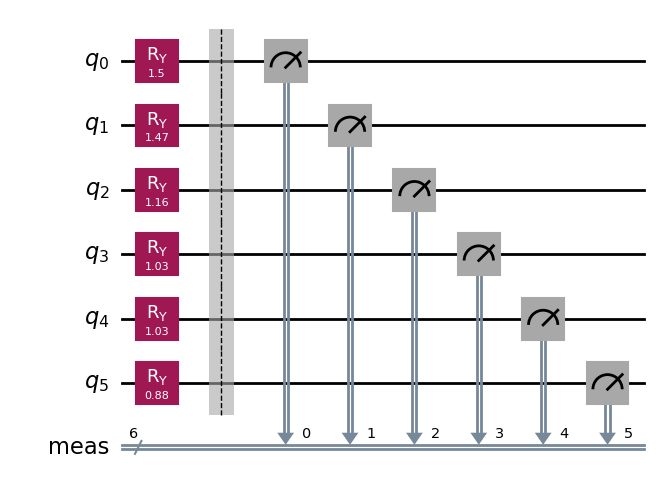

In [6]:
display(measured.draw(output="mpl", style="iqp", fold=-1))

## 4. Classical comparison and export

Exact reference: [scipy.stats.poisson_binom.sf](https://docs.scipy.org/doc/scipy-1.17.0/reference/generated/scipy.stats.poisson_binom.html).
`sf(2, p)` is P(S > 2), hence P(S >= 3).
Monte Carlo: `numpy.random.default_rng`, with the same number of trials as quantum shots.


In [7]:
exact_classical = float(poisson_binom.sf(THRESHOLD - 1, p))
rng = np.random.default_rng(SEED)
mc_subscriptions = (rng.random((shots, n)) < p).sum(axis=1)
mc_successes = int((mc_subscriptions >= THRESHOLD).sum())
mc_estimate = mc_successes / shots

comparison = pd.DataFrame({
    "method": ["exact_classical", "exact_statevector", "quantum_sampling", "classical_monte_carlo"],
    "probability": [exact_classical, exact_quantum, quantum_estimate, mc_estimate],
    "draws": [0, 0, shots, shots],
})
comparison["signed_error"] = comparison["probability"] - exact_classical
comparison["absolute_error"] = abs(comparison["signed_error"])
comparison.to_csv(COMPARISON_CSV, index=False)
display(comparison.round(6))


,method,probability,draws,signed_error,absolute_error
0,exact_classical,0.275925,0,0.000000,0.000000
1,exact_statevector,0.275925,0,0.000000,0.000000
2,quantum_sampling,0.277344,1024,0.001418,0.001418
3,classical_monte_carlo,0.304688,1024,0.028762,0.028762


Both sampled methods have standard error sqrt(P(1-P)/N).
A closer estimate for one fixed seed is sampling variation.
The campaign probability is conditional on the frozen model inputs and independence.


In [8]:
standard_error = float(np.sqrt(exact_classical * (1 - exact_classical) / shots))
print(f"Sampling standard error: {100 * standard_error:.3f} percentage points")

compiled = transpile(
    circuit, basis_gates=BASIS_GATES, optimization_level=1, seed_transpiler=SEED,
)
resources = []
for name, current in [("original", circuit), ("transpiled", compiled)]:
    resources.append({
        "circuit": name, "qubits": current.num_qubits, "depth": current.depth(),
        "one_qubit_gates": sum(g.operation.num_qubits == 1 for g in current.data),
        "two_qubit_gates": sum(g.operation.num_qubits == 2 for g in current.data),
        "swaps": int(current.count_ops().get("swap", 0)),
        "gate_counts": dict(current.count_ops()),
    })
display(pd.DataFrame(resources).drop(columns="gate_counts"))


Sampling standard error: 1.397 percentage points


,circuit,qubits,depth,one_qubit_gates,two_qubit_gates,swaps
0,original,6,1,6,0,0
1,transpiled,6,4,24,0,0


In [9]:
setup = {
    "source_stage2_depth": stage2["main_depth"], "threshold": THRESHOLD,
    "customers_assumed_independent": True, "ancillas": 0,
    "state_preparation": "Ry(2*arcsin(sqrt(p_i))) on qubit i, starting in zero",
    "qubit_order": "selected_ids[i] maps to qubit i; display q5...q0",
    "sampling": "StatevectorSampler default; no shot-count override", "shots": shots,
    "monte_carlo_trials": shots,
    "seeds": {"sampler": SEED, "monte_carlo": SEED, "transpiler": SEED},
    "backend": "Qiskit ideal statevector simulation on CPU", "device_noise_model": None,
    "physical_hardware_used": False, "basis_gates": BASIS_GATES,
    "optimization_level": 1, "hardware_target": None,
    "stage1_predictions_sha256": sha256(STAGE1_CSV.read_bytes()).hexdigest(),
    "stage2_results_sha256": sha256(STAGE2_JSON.read_bytes()).hexdigest(),
}


In [10]:
report = {
    "setup": setup, "selected_ids": ids,
    "customer_to_qubit": qubit_table.to_dict(orient="records"),
    "exact_probability": exact_classical, "exact_quantum_probability": exact_quantum,
    "quantum_estimate": quantum_estimate, "quantum_successes": quantum_successes,
    "monte_carlo_estimate": mc_estimate, "monte_carlo_successes": mc_successes,
    "sampling_standard_error": standard_error, "expected_subscribers": float(p.sum()),
    "measurement_counts": {str(bits): int(count) for bits, count in counts.items()},
    "comparison": comparison.to_dict(orient="records"), "circuit_resources": resources,
    "versions": {package: version(package) for package in packages},
}
RESULTS_JSON.write_text(json.dumps(report, indent=2, allow_nan=False) + "\n")
print(f"Saved comparison to {COMPARISON_CSV} and campaign result to {RESULTS_JSON}")


Saved comparison to stage3_comparison.csv and campaign result to stage3_simulation.json
